<a href="https://colab.research.google.com/github/arth2436/Laundry.to/blob/main/CN7031_Week3_Sqoop_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CN7031 · Week 3 — Apache Sqoop: Moving Relational Data into HDFS

---

**Practical lab workbook | Big Data Analytics (CN7031) 2026-27**

**Dr Fahimeh Jafari** : [F.Jafari@uel.ac.uk](mailto:F.Jafari@uel.ac.uk)

With contributions from Mr Saieef Sunny : [u2887577@uel.ac.uk](mailto:u2887577@uel.ac.uk)


---

### Learning outcomes
By the end of this lab, you should be able to:
1. Run a **single-node HDFS cluster** and a **MySQL server** side by side in Google Colab.
2. Explore the `retail_db` relational database from the **MySQL command line**.
3. Use Sqoop's `list-databases`, `list-tables` and `eval` tools to **test a JDBC connection** before moving any data.
4. Import every `retail_db` table into HDFS with `sqoop import-all-tables`, and explain how the number of **mappers (`-m`)** relates to the output files.
5. Query the imported HDFS files with **SQL**, and explain why plain text files need a **schema supplied at read time**.
6. **Export** data from HDFS back into MySQL with `sqoop export`, and verify that the round trip lost nothing.

### What is Sqoop?
Organisations keep their day-to-day data (customers, orders, payments) in **relational databases** such as MySQL. To analyse that data at scale, it first has to be copied into Hadoop. **Apache Sqoop** ("SQL-to-Hadoop") is the tool built for that job:

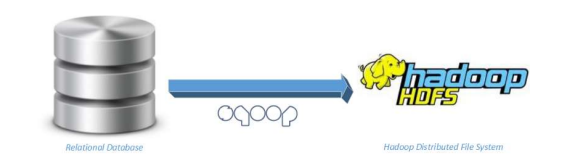

- `sqoop import` reads tables from a database through **JDBC** and writes them as files in **HDFS**;
- `sqoop export` reads files from HDFS and writes them back into a database table.

Sqoop does the copying with a **MapReduce job**, so a large table can be split into slices that several **mappers** read in parallel. Sqoop 1.4.7 is the final release (the project was retired in 2021), but it is still found in many existing Hadoop pipelines, and the same ideas carry over to modern tools such as Spark's JDBC reader.

### Three kinds of cell
This notebook imitates the three places you would type commands on a real Hadoop machine:

| A cell starting with… | Behaves like… | You type… |
| :-- | :-- | :-- |
| `%%bash` (or a line starting with `!`) | a **Linux terminal** (`$` prompt) | `hdfs dfs …`, `sqoop …` and other shell commands |
| `%%mysql` | the **`mysql>` prompt** | SQL statements for the MySQL database, each ending in `;` |
| `%%sql` | a **SQL editor over HDFS** (the job Hive or Impala does on a cluster) | SQL queries on the data Sqoop copied into HDFS (Section 5) |

Cells with a **▶ title** and hidden code prepare the lab. Run them, but you do not need to read or type their code.

### How to use the notebook
- Use **Google Colab → Python 3 → CPU**. Run the cells in order, starting from Section 1. On a fresh runtime, Section 1 takes roughly 5–8 minutes.
- Section 1 installs everything and loads the `retail_db` sample database automatically; there is nothing to upload.
- Everything runs on **one temporary Colab VM**: one NameNode, one DataNode and one MySQL server. Sqoop's MapReduce jobs run in Hadoop's **local mode** rather than on a YARN cluster. This is a teaching demonstration, **not** a production Hadoop cluster.
- The MySQL user `root` with password `cloudera` is a **teaching credential only**; never put real passwords on a command line.

**Important:** Do not reformat an existing NameNode or edit DataNode block files. Colab storage is temporary and is deleted when its runtime resets; if that happens, run Section 1 again.

## 1. Start HDFS, install Sqoop and load MySQL

**Goal:** Prepare the three pieces this lab needs on one Colab VM:

| Step | What it sets up | Role in this lab |
| :-- | :-- | :-- |
| **1.1** | Hadoop 3.5.0 (one NameNode + one DataNode) and **Apache Sqoop 1.4.7** | HDFS is the **destination**; Sqoop is the **transfer tool** |
| **1.2** | **MySQL 8** with the `retail_db` sample database | The relational **source** |
| **1.3** | A quick check that every service is running | Catches set-up problems before the exercises |

Both set-up cells are safe to rerun in the **same runtime**: they skip work that is already done and never reformat an existing NameNode.

### 1.1 Start HDFS and install Sqoop

**Goal:** Configure Hadoop 3.5.0 exactly as in Week 2: format the NameNode **once** on fresh storage, and start one NameNode and one DataNode. The same cell then installs **Apache Sqoop 1.4.7** and adds three Java libraries Sqoop needs:

| Library | Why Sqoop needs it |
| :-- | :-- |
| `mysql-connector-j-8.0.33.jar` | MySQL's **JDBC driver**, which lets Java programs such as Sqoop open `jdbc:mysql://` connections |
| `commons-lang-2.6.jar` | Sqoop 1.4.7 was built for Hadoop 2 and still calls this library, which Hadoop 3 no longer ships |
| `commons-cli-1.4.jar` | Sqoop reads its command-line options (`--connect`, `--username` …) with this library. Hadoop 3.5 ships a newer version that removed a method Sqoop calls, so Sqoop loads version 1.4 first. |

Two settings make Sqoop behave like it does on a cluster terminal:
- **Generated code.** For every table it copies, Sqoop writes and compiles a small Java class (Step 4.3). Here MapReduce runs in **local mode**, inside the Sqoop process, and can only load those classes from one known folder (`CODEGEN_DIR`). A small wrapper around the `sqoop` command adds that folder for you, so you type ordinary Sqoop commands.
- **Column order.** Sqoop 1.4.7 asks MySQL for a table's column names without saying what order it wants them in, and MySQL 8 sometimes returns them alphabetically. Sqoop would then write the columns in the wrong order. The wrapper uses a small fix, compiled in this cell, that asks for the columns in table order.
- **Readable output.** Sqoop's own progress messages are shown, but Hadoop's internal MapReduce messages are reduced to warnings and errors, so each command prints a short summary.

Every download is checked against the checksum published with it.

**Expected output:** `HDFS is ready ✓`, then `NameNode running · 1 DataNode running`, then `Sqoop 1.4.7 is ready ✓`. The initial Hadoop download is large and may take several minutes.

In [ ]:
# @title ▶ 1.1 Set up Hadoop 3.5.0 (one NameNode + one DataNode) and Apache Sqoop 1.4.7
# Import paths, operating-system utilities, download and checksum tools.
from pathlib import Path
import os
import subprocess
import urllib.request
import urllib.error
import hashlib
import re
import tarfile
import time

# Import XML tools to create Hadoop configuration files.
from xml.etree import ElementTree as ET

# Import the HTTP client used to check the NameNode and DataNode web services.
import requests

# Set a persistent path within the current temporary Colab runtime.
LAB = Path('/content/cn7031-week3-sqoop')
# Create the working directory when it does not exist.
LAB.mkdir(parents=True, exist_ok=True)
# Specify the Hadoop, Sqoop and Java paths.
HADOOP = LAB / 'hadoop-3.5.0'
SQOOP = LAB / 'sqoop-1.4.7.bin__hadoop-2.6.0'
JAVA = Path('/usr/lib/jvm/java-17-openjdk-amd64')
# Maven Central hosts the extra Java libraries Sqoop needs.
MAVEN = 'https://repo1.maven.org/maven2'

# Run a system command and stop with a useful error if it fails.
def checked(args, timeout=600):
    # Capture standard output and errors as readable text.
    p = subprocess.run(args, text=True, stdout=subprocess.PIPE,
                       stderr=subprocess.STDOUT, timeout=timeout)
    # Check the exit status before using the command's result.
    if p.returncode:
        raise RuntimeError(p.stdout[-5000:])
    # Return the printed output to the caller.
    return p.stdout

# Match a digest's length (in hexadecimal characters) to the algorithm that produced it.
DIGEST_BY_LENGTH = {32: 'md5', 40: 'sha1', 64: 'sha256', 128: 'sha512'}

# Read the first checksum file a publisher provides next to a download.
def published_digest(url, suffixes):
    # Remember the filename so it can be removed from the checksum text.
    name = url.rsplit('/', 1)[-1]
    for suffix in suffixes:
        try:
            # Download the small checksum file, e.g. file.tar.gz.sha512.
            with urllib.request.urlopen(url + suffix, timeout=60) as response:
                text = response.read().decode(errors='replace')
        except (urllib.error.URLError, TimeoutError):
            # Try the next checksum format if this one is not published.
            continue
        # Remove the filename, then keep only the hexadecimal groups.
        tokens = re.split(r'[\s:=()*]+', text.replace(name, ' '))
        digest = ''.join(t for t in tokens if re.fullmatch(r'[0-9a-fA-F]+', t)).lower()
        # Return the algorithm and digest when the length is recognised.
        if len(digest) in DIGEST_BY_LENGTH:
            return DIGEST_BY_LENGTH[len(digest)], digest
    # No usable checksum file was found.
    return None, None

# Download a file and keep it only if it matches the published checksum.
def download_verified(url, dest, suffixes, required=True):
    # Download into a temporary name so a failed check leaves nothing behind.
    partial = dest.with_name(dest.name + '.part')
    urllib.request.urlretrieve(url, partial)
    # Look up the publisher's checksum for this exact file.
    algorithm, expected = published_digest(url, suffixes)
    if algorithm is None:
        # Stop, unless this download is allowed to proceed without a checksum.
        if required:
            partial.unlink()
            raise RuntimeError(f'No checksum published for {url}. Stop here.')
        print(f'  Note: no checksum file found for {dest.name}; continuing without one.')
    else:
        # Calculate the digest of the downloaded file with the same algorithm.
        with partial.open('rb') as stream:
            actual = hashlib.file_digest(stream, algorithm).hexdigest()
        # Abort setup if the digests do not match.
        if actual != expected:
            partial.unlink()
            raise RuntimeError(f'Download checksum failed for {dest.name}. Stop here.')
        print(f'  {algorithm.upper()} checksum verified: {dest.name}')
    # Give the verified file its final name.
    partial.replace(dest)

# Install Java 17 only when it is not already available.
# Sqoop compiles Java code at run time, so it needs the compiler (javac) as well as java.
if not (JAVA / 'bin/javac').exists():
    # Update package metadata for the Colab VM.
    print('Installing Java …')
    checked(['apt-get', 'update', '-qq'])
    # Install the headless JDK required by Hadoop and Sqoop.
    checked(['apt-get', 'install', '-y', '-qq', 'openjdk-17-jdk-headless'])

# Download and verify Hadoop only once per current VM.
if not (HADOOP / '.verified').exists():
    # Identify the archive destination and Apache download URL.
    print('Downloading Hadoop from Apache (about 554 MB) …')
    archive = LAB / 'hadoop-3.5.0.tar.gz'
    base = 'https://downloads.apache.org/hadoop/common/hadoop-3.5.0/hadoop-3.5.0.tar.gz'
    # Keep track of progress so the display is not too noisy.
    last = [-1]

    # Report download progress in roughly 20% increments.
    def progress(count, block, total):
        # A known total size lets us calculate the percentage.
        if total > 0:
            percent = min(100, int(count * block * 100 / total))
            # Print only when a new progress interval is reached.
            if percent // 20 > last[0]:
                print(f'  Download: {percent}%')
                last[0] = percent // 20

    # Try the official mirror; use the Apache archive if unavailable.
    try:
        urllib.request.urlretrieve(base, archive, reporthook=progress)
    except (urllib.error.URLError, TimeoutError):
        # Use an archive URL instead of a missing current-release URL.
        base = base.replace('downloads.apache.org', 'archive.apache.org/dist')
        urllib.request.urlretrieve(base, archive, reporthook=progress)

    # Read Apache's published SHA-512 digest for this exact archive.
    with urllib.request.urlopen(base + '.sha512', timeout=60) as response:
        digest = re.findall(r'(?i)\b[0-9a-f]{128}\b', response.read().decode())
    # Calculate the SHA-512 digest of the downloaded file.
    with archive.open('rb') as stream:
        actual = hashlib.file_digest(stream, 'sha512').hexdigest()
    # Abort setup if the digests do not match.
    assert len(digest) == 1 and digest[0].lower() == actual, 'Download checksum failed. Stop here.'
    # Extract the verified archive safely.
    print('Checksum verified. Installing Hadoop …')
    with tarfile.open(archive) as bundle:
        bundle.extractall(LAB, filter='data')
    # Record successful verification and remove the compressed archive.
    (HADOOP / '.verified').write_text(actual)
    archive.unlink()

# Download and verify Sqoop only once per current VM.
if not (SQOOP / '.verified').exists():
    # Sqoop is a retired Apache project, so it is only kept in the Apache archive.
    print('Downloading Apache Sqoop 1.4.7 …')
    archive = LAB / 'sqoop-1.4.7.tar.gz'
    download_verified('https://archive.apache.org/dist/sqoop/1.4.7/sqoop-1.4.7.bin__hadoop-2.6.0.tar.gz',
                      archive, ('.sha512', '.sha1', '.md5'), required=False)
    # Extract the archive safely.
    print('Installing Sqoop …')
    with tarfile.open(archive) as bundle:
        bundle.extractall(LAB, filter='data')
    # Make sure Sqoop's launcher scripts are executable.
    for script in (SQOOP / 'bin').iterdir():
        script.chmod(script.stat().st_mode | 0o111)
    # Record successful installation and remove the compressed archive.
    (SQOOP / '.verified').write_text('ok')
    archive.unlink()

# Add the MySQL JDBC driver, commons-lang 2 and commons-cli 1.4 to Sqoop's library folder.
EXTRA_JARS = {
    'mysql-connector-j-8.0.33.jar': f'{MAVEN}/com/mysql/mysql-connector-j/8.0.33/mysql-connector-j-8.0.33.jar',
    'commons-lang-2.6.jar': f'{MAVEN}/commons-lang/commons-lang/2.6/commons-lang-2.6.jar',
    'commons-cli-1.4.jar': f'{MAVEN}/commons-cli/commons-cli/1.4/commons-cli-1.4.jar',
}
for name, url in EXTRA_JARS.items():
    # Download each library once; Maven Central publishes a .sha1 checksum for every file.
    if not (SQOOP / 'lib' / name).exists():
        print(f'Downloading {name} …')
        download_verified(url, SQOOP / 'lib' / name, ('.sha1',))

# Sqoop reads conf/sqoop-env.sh at every start: load commons-cli 1.4 ahead of Hadoop's newer copy,
# because Sqoop 1.4.7 reads its options with a commons-cli method that later versions removed.
(SQOOP / 'conf' / 'sqoop-env.sh').write_text(
    f'export HADOOP_CLIENT_OPTS="$HADOOP_CLIENT_OPTS -Xbootclasspath/a:{SQOOP / "lib" / "commons-cli-1.4.jar"}"\n')

# Create an empty folder to stand in for HBase, HCatalog, Accumulo and ZooKeeper (not used in this lab).
NOT_INSTALLED = LAB / 'not-installed'
NOT_INSTALLED.mkdir(exist_ok=True)

# Set Java, Hadoop and Sqoop environment variables for child processes (!, %%bash, sqoop).
os.environ.update(JAVA_HOME=str(JAVA), HADOOP_HOME=str(HADOOP),
                  HADOOP_CONF_DIR=str(HADOOP / 'etc/hadoop'),
                  HADOOP_LOG_DIR=str(LAB / 'logs'), HADOOP_PID_DIR=str(LAB / 'pids'),
                  # Sqoop finds Hadoop's client libraries through these two variables.
                  HADOOP_COMMON_HOME=str(HADOOP), HADOOP_MAPRED_HOME=str(HADOOP),
                  SQOOP_HOME=str(SQOOP),
                  # Pointing these at an empty folder silences Sqoop's "not installed" warnings.
                  HBASE_HOME=str(NOT_INSTALLED), HCAT_HOME=str(NOT_INSTALLED),
                  ACCUMULO_HOME=str(NOT_INSTALLED), ZOOKEEPER_HOME=str(NOT_INSTALLED))
# Give client programs (hdfs dfs, sqoop) 1 GB of memory and access to JDK internals that older Hadoop code uses.
os.environ['HADOOP_CLIENT_OPTS'] = ('-Xmx1g --add-opens=java.base/java.lang=ALL-UNNAMED '
                                    '--add-opens=java.base/java.util=ALL-UNNAMED '
                                    '--add-opens=java.base/java.nio=ALL-UNNAMED '
                                    '--add-opens=java.base/sun.nio.ch=ALL-UNNAMED')
# Folder for the Java code Sqoop generates and compiles for each table it copies.
CODEGEN = LAB / 'codegen'
CODEGEN.mkdir(exist_ok=True)
os.environ['CODEGEN_DIR'] = str(CODEGEN)

# Lab wrapper for the sqoop command. Tools that generate Java code (import, import-all-tables, export)
# write it to CODEGEN_DIR, and CODEGEN_DIR is put on Hadoop's classpath. In local mode the map tasks
# run inside the Sqoop process and can only load each table's class from that classpath.
WRAPPER_DIR = LAB / 'bin'
WRAPPER_DIR.mkdir(exist_ok=True)
(WRAPPER_DIR / 'sqoop').write_text(f"""#!/bin/bash
# CN7031 lab wrapper for Sqoop (see Step 1.1).
export CODEGEN_DIR="${{CODEGEN_DIR:-{CODEGEN}}}"
mkdir -p "$CODEGEN_DIR"
export HADOOP_CLASSPATH="$CODEGEN_DIR${{HADOOP_CLASSPATH:+:$HADOOP_CLASSPATH}}"
case "$1" in
  import|import-all-tables|export)
    tool="$1"; shift
    # For MySQL, read column names in table order (see the column-order fix below).
    extra=()
    case " $* " in
      *" --connection-manager"*|*" --driver"*) ;;
      *jdbc:mysql:*) extra=(--connection-manager cn7031.OrderedMySQLManager) ;;
    esac
    exec "{SQOOP}/bin/sqoop" "$tool" --outdir "$CODEGEN_DIR" --bindir "$CODEGEN_DIR" "${{extra[@]}}" "$@" ;;
  *)
    exec "{SQOOP}/bin/sqoop" "$@" ;;
esac
""")
(WRAPPER_DIR / 'sqoop').chmod(0o755)

# Show Sqoop's own progress messages, but only warnings and errors from Hadoop's internals,
# so each Sqoop command prints a readable summary instead of hundreds of MapReduce log lines.
log4j = HADOOP / 'etc/hadoop/log4j.properties'
QUIET = ['log4j.logger.org.apache.hadoop=WARN',
         'log4j.logger.org.apache.sqoop=INFO',
         # Harmless in local mode: Hadoop tries to link each job's libraries into the current folder
         # and warns when it cannot. The job still succeeds, so hide these "failed" warnings.
         'log4j.logger.org.apache.hadoop.fs.FileUtil=ERROR',
         'log4j.logger.org.apache.hadoop.mapred.LocalDistributedCacheManager=ERROR',
         'log4j.logger.org.apache.hadoop.metrics2.impl.MetricsSystemImpl=ERROR']
if log4j.exists():
    text = log4j.read_text()
    missing = [line for line in QUIET if line not in text]
    if missing:
        log4j.write_text(text + '\n# CN7031: quieter client output\n' + '\n'.join(missing) + '\n')

# Put the lab wrapper, Sqoop, Hadoop and Java executables on the shell PATH (wrapper first).
os.environ['PATH'] = f'{WRAPPER_DIR}:{SQOOP}/bin:{HADOOP}/bin:{JAVA}/bin:' + os.environ['PATH']

# Column-order fix. Sqoop 1.4.7 reads a MySQL table's column names from INFORMATION_SCHEMA without
# ORDER BY. MySQL 8 does not guarantee an order without one and sometimes returns them alphabetically,
# so Sqoop would write the columns in the wrong order (e.g. 2|1|Football instead of 1|2|Football).
# This small connection manager adds ORDER BY ORDINAL_POSITION; the sqoop wrapper above uses it.
FIX_JAR = SQOOP / 'lib' / 'cn7031-ordered-mysql-manager.jar'
if not FIX_JAR.exists():
    fix_src = LAB / 'sqoop-fix' / 'src' / 'cn7031'
    fix_cls = LAB / 'sqoop-fix' / 'classes'
    fix_src.mkdir(parents=True, exist_ok=True)
    fix_cls.mkdir(parents=True, exist_ok=True)
    (fix_src / 'OrderedMySQLManager.java').write_text("""package cn7031;

import com.cloudera.sqoop.SqoopOptions;
import org.apache.sqoop.manager.MySQLManager;

/** MySQLManager that lists a table's columns in table order (Sqoop 1.4.7 omits ORDER BY). */
public class OrderedMySQLManager extends MySQLManager {
  public OrderedMySQLManager(final SqoopOptions opts) {
    super(opts);
  }

  @Override
  protected String getListColumnsQuery(String tableName) {
    return super.getListColumnsQuery(tableName) + " ORDER BY ORDINAL_POSITION";
  }
}
""")
    # Compile against Sqoop's own jar, its libraries and Hadoop's client libraries, then package it.
    hadoop_cp = subprocess.run([str(HADOOP / 'bin/hadoop'), 'classpath'], capture_output=True,
                               text=True, check=True).stdout.strip().splitlines()[-1]
    sqoop_jar = next(SQOOP.glob('sqoop-1.4.7*.jar'))
    checked([str(JAVA / 'bin/javac'), '-nowarn', '-cp', f'{sqoop_jar}:{SQOOP}/lib/*:{hadoop_cp}',
             '-d', str(fix_cls), str(fix_src / 'OrderedMySQLManager.java')])
    checked([str(JAVA / 'bin/jar'), 'cf', str(FIX_JAR), '-C', str(fix_cls), '.'])
# Make separate folders for namespace metadata, blocks, logs and process IDs.
for name in ('namenode', 'datanode', 'logs', 'pids'):
    (LAB / name).mkdir(exist_ok=True)

# Write a Hadoop XML configuration file from a property dictionary.
def config(name, values):
    # Create the configuration root element.
    root = ET.Element('configuration')
    # Add each property name and its value.
    for key, value in values.items():
        property_node = ET.SubElement(root, 'property')
        ET.SubElement(property_node, 'name').text = key
        ET.SubElement(property_node, 'value').text = str(value)
    # Save the resulting configuration into Hadoop's config directory.
    ET.ElementTree(root).write(HADOOP / 'etc/hadoop' / name, encoding='utf-8')

# Point HDFS clients at the local NameNode using port 9000.
config('core-site.xml', {
    'fs.defaultFS': 'hdfs://127.0.0.1:9000',
    'hadoop.tmp.dir': str(LAB / 'tmp')
})
# Assign local storage directories and a default replication factor of one.
config('hdfs-site.xml', {
    'dfs.namenode.name.dir': (LAB / 'namenode').as_uri(),
    'dfs.datanode.data.dir': (LAB / 'datanode').as_uri(),
    'dfs.replication': 1,
    # Bind RPC and health-report endpoints to the VM's loopback address.
    'dfs.namenode.rpc-address': '127.0.0.1:9000',
    'dfs.namenode.rpc-bind-host': '127.0.0.1',
    'dfs.namenode.http-address': '127.0.0.1:9870',
    'dfs.namenode.http-bind-host': '127.0.0.1',
    # Keep DataNode transfer, HTTP and IPC endpoints on localhost.
    'dfs.datanode.address': '127.0.0.1:9866',
    'dfs.datanode.http.address': '127.0.0.1:9864',
    'dfs.datanode.ipc.address': '127.0.0.1:9867',
    'dfs.datanode.hostname': '127.0.0.1',
    'dfs.client.use.datanode.hostname': 'true',
    'dfs.datanode.use.datanode.hostname': 'true',
})
# Run Sqoop's MapReduce jobs in local mode (inside the Sqoop process, no YARN cluster).
config('mapred-site.xml', {
    'mapreduce.framework.name': 'local',
    # Keep each job's temporary staging files in one HDFS folder.
    'mapreduce.jobtracker.staging.root.dir': '/tmp/hadoop-staging',
})

# Read Hadoop's environment shell script before adding Java and heap settings.
env = HADOOP / 'etc/hadoop/hadoop-env.sh'
# Avoid appending duplicate configuration lines on reruns.
if 'export HADOOP_HEAPSIZE_MAX=512' not in env.read_text():
    env.write_text(env.read_text() +
                   f'\n# CN7031 HDFS environment\nexport JAVA_HOME={JAVA}\nexport HADOOP_HEAPSIZE_MAX=512\n')

# Format only when no NameNode filesystem already exists.
if not (LAB / 'namenode/current/VERSION').exists():
    # Never silently overwrite an unexpectedly populated storage directory.
    assert all(not any((LAB / name).iterdir()) for name in ('namenode', 'datanode')), \
        'Existing storage found. Do not reformat it.'
    # Give the new HDFS namespace a fixed educational cluster ID.
    checked(['hdfs', 'namenode', '-format', '-nonInteractive', '-clusterid', 'CID-cn7031-week3'])

# Start a service only if its local HTTP endpoint is not responding.
for daemon, port in [('namenode', 9870), ('datanode', 9864)]:
    try:
        # Raise an error on a missing or unhealthy service endpoint.
        requests.get(f'http://127.0.0.1:{port}/jmx', timeout=2).raise_for_status()
    except requests.RequestException:
        # Start the selected Hadoop daemon in the background.
        checked(['hdfs', '--daemon', 'start', daemon])

# Wait until the NameNode reports exactly one live DataNode.
for attempt in range(45):
    try:
        # Query NameNode's JMX metrics over its local HTTP endpoint.
        response = requests.get('http://127.0.0.1:9870/jmx',
                                params={'qry': 'Hadoop:service=NameNode,name=FSNamesystemState'},
                                timeout=3)
        response.raise_for_status()
        # Exit the retry loop when the teaching cluster is ready.
        if response.json()['beans'][0]['NumLiveDataNodes'] == 1:
            break
    except (requests.RequestException, KeyError, IndexError):
        # Retry while the services finish their startup sequence.
        pass
    # Pause two seconds before asking again.
    time.sleep(2)
else:
    # Stop if the DataNode never becomes available.
    raise RuntimeError('Startup failed. Inspect the Hadoop logs in /content/cn7031-week3-sqoop/logs.')

# Wait until the NameNode has left safe mode, allowing writes.
checked(['hdfs', 'dfsadmin', '-safemode', 'wait'], timeout=90)
# Ask Sqoop for its version; this proves Sqoop can load Hadoop and its libraries.
version = next((line for line in checked(['sqoop', 'version'], timeout=180).splitlines()
                if line.startswith('Sqoop ')), 'Sqoop (version not found)')
# Ask for help on one tool; this makes Sqoop parse its options, which needs commons-cli 1.4.
checked(['sqoop', 'help', 'list-databases'], timeout=180)
# Confirm that HDFS and Sqoop are usable before the exercises begin.
print('\nHDFS is ready ✓')
print('Hadoop 3.5.0 · NameNode running · 1 DataNode running')
print(f'{version} is ready ✓ · MySQL JDBC driver 8.0.33 · column-order fix installed')

Installing Java …
  Download: 0%
  Download: 20%
  Download: 40%
  Download: 60%
  Download: 80%
  Download: 100%
Checksum verified. Installing Hadoop …
  MD5 checksum verified: sqoop-1.4.7.tar.gz
Installing Sqoop …
  SHA1 checksum verified: mysql-connector-j-8.0.33.jar
  SHA1 checksum verified: commons-lang-2.6.jar
  SHA1 checksum verified: commons-cli-1.4.jar

HDFS is ready ✓
Hadoop 3.5.0 · NameNode running · 1 DataNode running
Sqoop 1.4.7 is ready ✓ · MySQL JDBC driver 8.0.33 · column-order fix installed


### 1.2 Install MySQL and load `retail_db`

**Goal:** Create the **source database** that Sqoop will copy from. The cell:
1. installs the **MySQL 8** server and starts it;
2. gives the MySQL `root` account the password `cloudera`;
3. loads `retail_db` from a SQL dump file (a text file of `CREATE TABLE` and `INSERT` statements), after checking the file is the expected one;
4. turns on **`%%mysql` cells**: the lines you type in such a cell are sent to the `mysql` client, exactly as if you typed them at the `mysql>` prompt.

The login is stored in `~/.my.cnf`, a MySQL **option file**, so neither `%%mysql` cells nor `mysql` commands ask for the password.

**Expected output:** `MySQL is ready ✓`, six tables with their row counts (for example, `customers 12,435 rows`), then `%%mysql cells are ready ✓`.

In [ ]:
# @title ▶ 1.2 Install MySQL 8, set the root password and load retail_db
# Import process, checksum, download and path tools.
import os
import time
import hashlib
import subprocess
import urllib.request
from pathlib import Path

# Run a command quietly and return its result (check=True stops on errors).
def run(args, check=True, **kwargs):
    return subprocess.run(args, text=True, capture_output=True, check=check, **kwargs)

# Install the MySQL server package only when it is not already available.
if run(['which', 'mysqld'], check=False).returncode:
    # Update package metadata, then install without interactive questions.
    print('Installing MySQL server (about 1 minute) …')
    run(['apt-get', 'update', '-qq'])
    run(['apt-get', 'install', '-y', '-qq', 'mysql-server'],
        env={**os.environ, 'DEBIAN_FRONTEND': 'noninteractive'})

# Start the server (harmless if it is already running).
run(['service', 'mysql', 'start'], check=False)
# Wait until the server answers.
for attempt in range(30):
    if run(['mysqladmin', '--no-defaults', 'ping'], check=False).returncode == 0:
        break
    time.sleep(1)
else:
    # Stop if MySQL never starts.
    raise RuntimeError('MySQL did not start. Try Runtime → Restart session, then rerun Section 1.')

# A fresh install lets Linux root log in without a password; set the tutorial password once.
if run(['mysql', '--no-defaults', '-u', 'root', '-e', 'SELECT 1'], check=False).returncode == 0:
    run(['mysql', '--no-defaults', '-u', 'root', '-e',
         "ALTER USER 'root'@'localhost' IDENTIFIED WITH caching_sha2_password BY 'cloudera';"])

# Store the login in an option file so later mysql commands need no password prompt.
my_cnf = Path.home() / '.my.cnf'
my_cnf.write_text('[client]\nuser=root\npassword=cloudera\ndefault-character-set=utf8mb4\n')
# Make the option file readable by its owner only.
my_cnf.chmod(0o600)

# Load retail_db unless it is already complete (68,883 orders).
orders = run(['mysql', '-N', '-e', 'SELECT COUNT(*) FROM retail_db.orders'], check=False)
if orders.returncode or orders.stdout.strip() != '68883':
    # Use an uploaded copy if present; otherwise download the dump.
    dump = Path('/content/retail_db.sql')
    if not dump.exists():
        print('Downloading the retail_db SQL dump (about 10 MB) …')
        urllib.request.urlretrieve(
            'https://raw.githubusercontent.com/dgadiraju/retail_db/master/create_db.sql', dump)
    # Check the dump is byte-for-byte the copy this notebook was tested with.
    with dump.open('rb') as stream:
        actual = hashlib.file_digest(stream, 'sha256').hexdigest()
    assert actual == '90e630cec0d0030de82ccd2c49ad61668e7b9965f0a39f2639b233a56dede5ea', \
        'retail_db.sql is not the expected file. Delete /content/retail_db.sql and rerun this cell.'
    # Create an empty database and run the dump's SQL statements into it.
    print('Loading retail_db into MySQL …')
    run(['mysql', '-e', 'DROP DATABASE IF EXISTS retail_db; CREATE DATABASE retail_db;'])
    with dump.open() as sql:
        subprocess.run(['mysql', 'retail_db'], stdin=sql, check=True)

# Confirm that MySQL is usable, and report each table's row count.
version = run(['mysql', '-N', '-e', 'SELECT VERSION()']).stdout.strip()
print(f'\nMySQL is ready ✓ (server {version}, user root, password cloudera)')
for table in ['categories', 'customers', 'departments', 'order_items', 'orders', 'products']:
    rows = run(['mysql', '-N', '-e', f'SELECT COUNT(*) FROM retail_db.{table}']).stdout.strip()
    print(f'  retail_db.{table:<12} {int(rows):>8,} rows')

# Notebook shortcut: a %%mysql cell sends its lines to the mysql client, like typing them at the mysql> prompt.
from IPython.core.magic import register_cell_magic

@register_cell_magic
def mysql(line, cell):
    # -t draws result tables; -vv echoes each statement and reports "N rows in set" or "Query OK".
    result = subprocess.run(['mysql', '-t', '-vv', *line.split()], input=cell, text=True, capture_output=True)
    print(result.stdout + result.stderr, end='')

print('\n%%mysql cells are ready ✓')

Installing MySQL server (about 1 minute) …
Loading retail_db into MySQL …

MySQL is ready ✓ (server 8.0.46-0ubuntu0.24.04.4, user root, password cloudera)
  retail_db.categories         58 rows
  retail_db.customers      12,435 rows
  retail_db.departments         6 rows
  retail_db.order_items   172,198 rows
  retail_db.orders         68,883 rows
  retail_db.products        1,345 rows

%%mysql cells are ready ✓


### 1.3 Check the running services

**Goal:** Confirm that every service started before moving any data.

| Component | Responsibility | On this Colab VM |
| :-- | :-- | :-- |
| **NameNode** | Manages the HDFS namespace and records which DataNodes hold each block | One Java process |
| **DataNode** | Stores HDFS block data on disk and reports its state to the NameNode | One Java process |
| **MySQL server** | The relational source database (`retail_db`) | One `mysqld` process on port 3306 |
| **Sqoop** | Not a service: a command-line tool that starts a MapReduce job each time it runs | Nothing running until you call it |

`jps` lists the **Java** processes on this machine (`Jps` in its output is the listing tool itself); find `NameNode` and `DataNode`. MySQL is not written in Java, so check it with `mysqladmin status` instead. Process ID numbers change between sessions.

In [ ]:
# List local Java processes to confirm that both HDFS services started.
!jps

4133 DataNode
4070 NameNode
6430 Jps


In [ ]:
# Ask the MySQL server whether it is alive and how long it has been running.
!mysqladmin status

Uptime: 10  Threads: 2  Questions: 132  Slow queries: 0  Opens: 167  Flush tables: 3  Open tables: 80  Queries per second avg: 13.200


## 2. Explore `retail_db` in MySQL

**Goal:** Get to know the source data **before** copying it. Sqoop imports tables exactly as the database describes them, so knowing the tables, their columns and their sizes lets you check Sqoop's work later.

`retail_db` is a sample online sports shop. Six tables describe what is sold and who bought it:

| Table | One row per… | Primary key | Links to |
| :-- | :-- | :-- | :-- |
| `departments` | store department | `department_id` | – |
| `categories` | product category | `category_id` | `departments` via `category_department_id` |
| `products` | product | `product_id` | `categories` via `product_category_id` |
| `customers` | customer | `customer_id` | – |
| `orders` | order | `order_id` | `customers` via `order_customer_id` |
| `order_items` | line on an order | `order_item_id` | `orders` and `products` |

**Working at the `mysql>` prompt.** Each `%%mysql` cell is one session: MySQL echoes every statement between dashed lines, then prints its result and a summary such as `6 rows in set`; `Bye` means the session has closed. Because every cell starts a fresh session, begin with `USE retail_db;` whenever you need that database.

Two SQL habits to keep in mind:
- Every MySQL statement ends with a semicolon `;`.
- SQL keywords are usually written in UPPERCASE and names in lowercase for readability; MySQL itself does not care.

### 2.1 Show the databases

**Goal:** See which databases the MySQL server holds. A new server contains four **system databases** that MySQL uses to run itself (`information_schema`, `mysql`, `performance_schema`, `sys`), plus the `retail_db` database loaded in Step 1.2.

In [ ]:
#Show every database on this MySQL server.
%%mysql
SHOW DATABASES;

--------------
SHOW DATABASES
--------------

+--------------------+
| Database           |
+--------------------+
| information_schema |
| mysql              |
| performance_schema |
| retail_db          |
| sys                |
+--------------------+
5 rows in set

Bye


### 2.2 Select `retail_db` and list its tables

**Goal:** List the tables Sqoop will copy in Section 4. `USE` selects a database for the rest of the session.

**Expected:** six tables.

In [ ]:
# Select the retail_db database for this session.
%%mysql
USE retail_db;
SHOW TABLES;

--------------
SHOW TABLES
--------------

+---------------------+
| Tables_in_retail_db |
+---------------------+
| categories          |
| customers           |
| departments         |
| order_items         |
| orders              |
| products            |
+---------------------+
6 rows in set

Bye


### 2.3 Describe a table

**Goal:** See a table's structure. `DESCRIBE` shows each column's name, SQL type and key. Sqoop reads exactly this information when it imports a table, and uses it to decide how to store each value (Step 4.3) and how to split the table between mappers (it uses the **primary key**, marked `PRI`).

In [ ]:
# Show each column's name, SQL type and key.
%%mysql
USE retail_db;
SHOW TABLES;

--------------
SHOW TABLES
--------------

+---------------------+
| Tables_in_retail_db |
+---------------------+
| categories          |
| customers           |
| departments         |
| order_items         |
| orders              |
| products            |
+---------------------+
6 rows in set

Bye


### 2.4 Count the rows in every table

**Goal:** Record how many rows each table holds. Sqoop prints `Retrieved N records` for each table it imports, and Step 4.2 compares these numbers with what landed in HDFS. Matching counts are the first proof that a transfer worked.

`UNION ALL` stacks the results of several `SELECT` statements into one table.

In [ ]:
# Count the rows in every table; keep these numbers to check the import in Step 4.2.
%%mysql
USE retail_db;
DESCRIBE customers;

--------------
DESCRIBE customers
--------------

+-------------------+--------------+------+-----+---------+----------------+
| Field             | Type         | Null | Key | Default | Extra          |
+-------------------+--------------+------+-----+---------+----------------+
| customer_id       | int          | NO   | PRI | NULL    | auto_increment |
| customer_fname    | varchar(45)  | NO   |     | NULL    |                |
| customer_lname    | varchar(45)  | NO   |     | NULL    |                |
| customer_email    | varchar(45)  | NO   |     | NULL    |                |
| customer_password | varchar(45)  | NO   |     | NULL    |                |
| customer_street   | varchar(255) | NO   |     | NULL    |                |
| customer_city     | varchar(45)  | NO   |     | NULL    |                |
| customer_state    | varchar(45)  | NO   |     | NULL    |                |
| customer_zipcode  | varchar(45)  | NO   |     | NULL    |                |
+-------------------+-----

## 3. Connect Sqoop to MySQL

**Goal:** Give Sqoop the address of the database and check that it can log in, before starting any long-running import.

Sqoop is a Java program, so it reaches MySQL through **JDBC** (Java Database Connectivity). A JDBC **connection string** says which driver to use, where the server is, which database to open, and any connection options:

```
jdbc:mysql://localhost:3306/retail_db?useSSL=false&allowPublicKeyRetrieval=true&zeroDateTimeBehavior=CONVERT_TO_NULL
└─driver─┘ └──host:port──┘ └database┘ └──────────────── connection options ────────────────────────────────┘
```

| Part | Meaning |
| :-- | :-- |
| `jdbc:mysql://` | Use the MySQL JDBC driver installed in Step 1.1 |
| `localhost:3306` | The MySQL server on this VM, on MySQL's standard port |
| `retail_db` | The database to open |
| `useSSL=false` | The server is on the same VM, so the connection is not encrypted (never do this across a network) |
| `allowPublicKeyRetrieval=true` | Lets the driver complete MySQL 8's password exchange without SSL |
| `zeroDateTimeBehavior=CONVERT_TO_NULL` | Sqoop 1.4.7 otherwise adds an older spelling of this option that the MySQL 8 driver rejects |

### 3.1 Store the connection strings

**Goal:** Avoid retyping the long JDBC strings. In a terminal you would store them in **environment variables** with `export NAME=value`; in Colab, `%env NAME=value` does the same. Afterwards, `"$RETAIL_JDBC"` in a command expands to the full string.

| Variable | Used for |
| :-- | :-- |
| `MYSQL_JDBC` | The MySQL **server**, with no database (Step 3.2) |
| `RETAIL_JDBC` | The **`retail_db` database** (every other Sqoop command) |

**Expected output:** each variable echoed back as `env: NAME=…`.

In [ ]:
# @title
%env MYSQL_JDBC=jdbc:mysql://localhost:3306/?useSSL=false&allowPublicKeyRetrieval=true&zeroDateTimeBehavior=CONVERT_TO_NULL
%env RETAIL_JDBC=jdbc:mysql://localhost:3306/retail_db?useSSL=false&allowPublicKeyRetrieval=true&zeroDateTimeBehavior=CONVERT_TO_NULL

env: MYSQL_JDBC=jdbc:mysql://localhost:3306/?useSSL=false&allowPublicKeyRetrieval=true&zeroDateTimeBehavior=CONVERT_TO_NULL
env: RETAIL_JDBC=jdbc:mysql://localhost:3306/retail_db?useSSL=false&allowPublicKeyRetrieval=true&zeroDateTimeBehavior=CONVERT_TO_NULL


### Test the connection before moving data

Steps 3.2–3.4 use three small Sqoop tools that talk to MySQL **directly**. They start no MapReduce job and write nothing to HDFS, so they are quick and safe. If they work, the driver, the password and the connection options are all correct.

| Tool | What it does | Compare with |
| :-- | :-- | :-- |
| `sqoop list-databases` | Lists the databases the account can see | Step 2.1 (`SHOW DATABASES`) |
| `sqoop list-tables` | Lists the tables in one database | Step 2.2 (`SHOW TABLES`) |
| `sqoop eval` | Runs one SQL statement on the database and prints the result | Step 5.5, which runs the same query on the HDFS copy |

A long command can be split over several lines by ending each line with a **backslash** `\`, as in any Linux terminal.

**Reading Sqoop's output.** Sqoop prints its **result** and its **log messages**, each message with a timestamp and a level (`INFO`, `WARN`, `ERROR`). Two messages appear every time and are harmless:
- the `WARN` about setting the password on the command line (in real work, use `-P` to be prompted for it, or `--password-file`);
- the note that the driver class `com.mysql.jdbc.Driver` is deprecated.

### 3.2 List the databases with Sqoop

**Goal:** Prove Sqoop can log in to the MySQL **server**, using the server-level string `$MYSQL_JDBC`.

**First time you see:**

| Command / option | What it does |
| :-- | :-- |
| `sqoop list-databases` | Runs Sqoop's `list-databases` tool. Every Sqoop command has the form `sqoop <tool> <options>`. |
| `--connect "…"` | The JDBC connection string of the database to talk to |
| `--username root` | The database account to log in as |
| `--password cloudera` | That account's password |
| `\` at the end of a line | Continues the same command on the next line |

**Expected:** the same five databases as Step 2.1.

In [ ]:
# List the databases the root account can see, this time through Sqoop and JDBC.
# --connect gives the connection string ($MYSQL_JDBC points at the server, no database).
# --username and --password give the login.
%%bash
sqoop list-databases \
   --connect "$MYSQL_JDBC" \
   --username root \
   --password  cloudera

mysql
information_schema
performance_schema
sys
retail_db


2026-10-19 17:17:44,898 INFO sqoop.Sqoop: Running Sqoop version: 1.4.7
2026-10-19 17:17:44,999 WARN tool.BaseSqoopTool: Setting your password on the command-line is insecure. Consider using -P instead.
2026-10-19 17:17:45,357 INFO manager.MySQLManager: Preparing to use a MySQL streaming resultset.
Loading class `com.mysql.jdbc.Driver'. This is deprecated. The new driver class is `com.mysql.cj.jdbc.Driver'. The driver is automatically registered via the SPI and manual loading of the driver class is generally unnecessary.


### 3.3 List the tables with Sqoop

**Goal:** Prove Sqoop can open `retail_db`. From here on, every command uses the database-level string `$RETAIL_JDBC`.

**Expected:** the same six tables as Step 2.2. These are exactly the tables `sqoop import-all-tables` will copy in Section 4.

In [ ]:
# List the tables inside retail_db ($RETAIL_JDBC points at that database).
%%bash
sqoop list-tables \
   --connect "$RETAIL_JDBC" \
   --username root \
   --password  cloudera

categories
customers
departments
order_items
orders
products


2026-10-19 17:17:47,143 INFO sqoop.Sqoop: Running Sqoop version: 1.4.7
2026-10-19 17:17:47,210 WARN tool.BaseSqoopTool: Setting your password on the command-line is insecure. Consider using -P instead.
2026-10-19 17:17:47,422 INFO manager.MySQLManager: Preparing to use a MySQL streaming resultset.
Loading class `com.mysql.jdbc.Driver'. This is deprecated. The new driver class is `com.mysql.cj.jdbc.Driver'. The driver is automatically registered via the SPI and manual loading of the driver class is generally unnecessary.


### 3.4 Run a query with `sqoop eval`

**Goal:** Run a SQL query on MySQL through Sqoop. `sqoop eval` is useful for checking data **before** an import, for example to see how many rows a filter would select.

**First time you see:** `--query "…"`, the SQL statement to run. It is wrapped in double quotes so the shell passes the whole statement to Sqoop as one argument.

This query counts the orders in each status. Keep the result: Step 5.5 runs the same query on the **HDFS copy**, and the numbers should match.

In [ ]:
# Run one SQL query on MySQL through Sqoop and print the result as a table.
%%bash
sqoop eval \
   --connect "$RETAIL_JDBC" \
   --username root \
   --password  cloudera \
   --query "SELECT order_status, COUNT(*) AS orders FROM orders GROUP BY order_status ORDER BY orders DESC"

----------------------------------------------
| order_status         | orders              | 
----------------------------------------------
| COMPLETE             | 22899               | 
| PENDING_PAYMENT      | 15030               | 
| PROCESSING           | 8275                | 
| PENDING              | 7610                | 
| CLOSED               | 7556                | 
| ON_HOLD              | 3798                | 
| SUSPECTED_FRAUD      | 1558                | 
| CANCELED             | 1428                | 
| PAYMENT_REVIEW       | 729                 | 
----------------------------------------------


2026-10-19 17:17:51,636 INFO sqoop.Sqoop: Running Sqoop version: 1.4.7
2026-10-19 17:17:51,709 WARN tool.BaseSqoopTool: Setting your password on the command-line is insecure. Consider using -P instead.
2026-10-19 17:17:51,936 INFO manager.MySQLManager: Preparing to use a MySQL streaming resultset.
Loading class `com.mysql.jdbc.Driver'. This is deprecated. The new driver class is `com.mysql.cj.jdbc.Driver'. The driver is automatically registered via the SPI and manual loading of the driver class is generally unnecessary.


## 4. Import every table into HDFS

**Goal:** Copy all six `retail_db` tables from MySQL into HDFS with one command, `sqoop import-all-tables`. Each table becomes its own HDFS directory under `/user/hive/warehouse`, the folder Hive and Impala use for their tables.

For **each table**, Sqoop:
1. reads the table's columns and SQL types through JDBC (the information you saw in Step 2.3);
2. **generates and compiles a Java class** that can hold one row of the table (see Step 4.3);
3. asks MySQL for the smallest and largest **primary key**, and divides that range between the **mappers** (`-m`);
4. runs a **map-only MapReduce job**: each mapper runs `SELECT … WHERE key >= … AND key < …` for its slice and writes one file, `part-m-0000N`.

**About `-m` in this lab.** On a cluster, `-m 2` runs two mappers in parallel and writes two files per table (`part-m-00000` and `part-m-00001`); more mappers copy faster but open more connections to the source database. In this Colab lab MapReduce runs in **local mode**, where Sqoop runs a single map task, so each table arrives as **one** `part-m-00000` file. The command is still written as it would be for a cluster.

### 4.1 Run the import

**Goal:** Run the import and watch Sqoop report each table.

| Option | Meaning |
| :-- | :-- |
| `-m 2` | Ask for two mappers per table (one is used in local mode; see above) |
| `--connect "$RETAIL_JDBC"`, `--username`, `--password` | Where the data comes from and how to log in |
| `--fields-terminated-by '\|'` | Separate columns with `\|` instead of Sqoop's default comma. Product 685 is called *TaylorMade SLDR Irons - (Steel) 4-PW**,** AW*; with commas, that one name would split into two columns. |
| `--warehouse-dir /user/hive/warehouse` | Parent HDFS directory; each table gets a sub-directory named after it |

The first command deletes any earlier copy, because Sqoop refuses to write into a table directory that already exists.

**First time you see:** `hdfs dfs -rm -r -f <path>`

| Part | What it does |
| :-- | :-- |
| `hdfs dfs` | Runs a file-system command on **HDFS** (not on Colab's own disk) |
| `-rm` | Removes a file or directory |
| `-r` | **Recursive**: removes a directory together with everything inside it |
| `-f` | **Force**: no error if the path does not exist (useful the first time you run the cell) |

For each table, look for three lines:
- `Beginning import of …`
- `Transferred … in … seconds`
- `Retrieved N records.`

The two `Note:` lines per table come from the Java compiler and are harmless.

**Expected:** six tables imported, with the record counts from Step 2.4. **Expected time:** 1–3 minutes.

In [ ]:
# Delete any earlier import: Sqoop refuses to write into a table directory that already exists.
!hdfs dfs -rm -r -f /user/hive/warehouse

In [ ]:
# Import every table of retail_db into HDFS, one sub-directory per table.
%%bash
sqoop import-all-tables \
   -m 2 \
   --connect "$RETAIL_JDBC" \
   --username root \
   --password  cloudera \
   --fields-terminated-by '|' \
   --warehouse-dir /user/hive/warehouse

2026-10-19 17:18:04,500 INFO sqoop.Sqoop: Running Sqoop version: 1.4.7
2026-10-19 17:18:04,561 WARN tool.BaseSqoopTool: Setting your password on the command-line is insecure. Consider using -P instead.
2026-10-19 17:18:04,678 INFO manager.MySQLManager: Preparing to use a MySQL streaming resultset.
Loading class `com.mysql.jdbc.Driver'. This is deprecated. The new driver class is `com.mysql.cj.jdbc.Driver'. The driver is automatically registered via the SPI and manual loading of the driver class is generally unnecessary.
2026-10-19 17:18:05,250 INFO tool.CodeGenTool: Beginning code generation
2026-10-19 17:18:05,335 INFO manager.SqlManager: Executing SQL statement: SELECT t.* FROM `categories` AS t LIMIT 1
2026-10-19 17:18:05,393 INFO manager.SqlManager: Executing SQL statement: SELECT t.* FROM `categories` AS t LIMIT 1
2026-10-19 17:18:05,404 INFO orm.CompilationManager: HADOOP_MAPRED_HOME is /content/cn7031-week3-sqoop/hadoop-3.5.0
Note: /content/cn7031-week3-sqoop/codegen/categories.

### 4.2 Verify the import in HDFS

**Goal:** Check that the data really arrived, in the shape we expect.

Each table should now be an HDFS **directory**. Inside `categories` you should find:
- `_SUCCESS`: an empty marker file written when the MapReduce job finishes without errors;
- `part-m-00000`: the data, written by the map task (`m` = map).

**First time you see:** `hdfs dfs -ls <path>` lists a directory in HDFS. Each line shows the permissions (`d` at the start means a directory), the replication factor (`-` for directories), the owner and group, the size in bytes, the date and time, and the full path.

In [ ]:
# List the table directories Sqoop created in HDFS (one per table).
!hdfs dfs -ls /user/hive/warehouse/

Found 6 items
drwxr-xr-x   - root supergroup          0 2026-10-19 17:18 /user/hive/warehouse/categories
drwxr-xr-x   - root supergroup          0 2026-10-19 17:18 /user/hive/warehouse/customers
drwxr-xr-x   - root supergroup          0 2026-10-19 17:18 /user/hive/warehouse/departments
drwxr-xr-x   - root supergroup          0 2026-10-19 17:18 /user/hive/warehouse/order_items
drwxr-xr-x   - root supergroup          0 2026-10-19 17:18 /user/hive/warehouse/orders
drwxr-xr-x   - root supergroup          0 2026-10-19 17:18 /user/hive/warehouse/products


In [ ]:
# List the files of one table: _SUCCESS marks a finished job, part-m-00000 holds the data.
!hdfs dfs -ls /user/hive/warehouse/categories/

Found 2 items
-rw-r--r--   1 root supergroup          0 2026-10-19 17:18 /user/hive/warehouse/categories/_SUCCESS
-rw-r--r--   1 root supergroup       1029 2026-10-19 17:18 /user/hive/warehouse/categories/part-m-00000


Now look **inside** a part file. Each line is one table row, with the columns separated by `|`. The file holds only values: no column names and no types.

**First time you see:**

| Command | What it does |
| :-- | :-- |
| `hdfs dfs -cat <file>` | Prints the whole contents of an HDFS file |
| `\|` (pipe) | Sends the output of the command on its left into the command on its right |
| `head -n 5` | Keeps only the first 5 lines |

When `head` stops reading early, `hdfs dfs -cat` may report `Unable to write to output stream`; that message is harmless.

In [ ]:
# Print the first five rows of a part file; columns are separated by |.
!hdfs dfs -cat /user/hive/warehouse/categories/part-m-00000 | head -n 5

1|2|Football
2|2|Soccer
3|2|Baseball & Softball
4|2|Basketball
5|2|Lacrosse


Search a table's files for one row with `grep`. Product 685 shows why `|` was the safer delimiter: its name contains a comma, but the line still splits into exactly six columns.

**First time you see:**

| Command | What it does |
| :-- | :-- |
| `part-m-*` | A **wildcard**: `*` matches any characters, so this means every part file of the table |
| `grep '^685\|'` | Prints only the lines that match the pattern. `^` means "at the start of the line", so this finds the line beginning `685\|` |

In [ ]:
# Find product 685, whose name contains a comma, in all part files of products.
!hdfs dfs -cat /user/hive/warehouse/products/part-m-* | grep '^685|'

685|31|TaylorMade SLDR Irons - (Steel) 4-PW, AW||899.99|http://images.acmesports.sports/TaylorMade+SLDR+Irons+-+%28Steel%29+4-PW%2C+AW


**Did every row arrive?** The loop below runs two commands for each table and prints the results side by side:
- `hdfs dfs -cat … | wc -l` counts the **lines** in HDFS (one line per row);
- `mysql -N -e "SELECT COUNT(*) …"` counts the **rows** in MySQL (`-N` drops the column heading).

**First time you see:**

| Command | What it does |
| :-- | :-- |
| `for t in …; do … done` | A shell **loop**: runs the lines between `do` and `done` once per table name, with the name in `$t` |
| `$( … )` | Runs the command inside and uses its output as a value |
| `wc -l` | Counts lines (`wc` = word count, `-l` = lines) |
| `mysql -N -e "…"` | Runs one SQL statement from the shell: `-e` = execute this statement, `-N` = no column heading |
| `echo` | Prints text |

**Expected:** the two numbers match for every table.

In [ ]:
# For each table, count the lines in HDFS and the rows in MySQL, and print both.
%%bash
for t in categories customers departments order_items orders products; do
    hdfs_rows=$(hdfs dfs -cat /user/hive/warehouse/${t}/part-m-00000 | wc -l)
    mysql_rows=$(mysql -N -e "SELECT COUNT(*) FROM retail_db.${t}")
    echo "HDFS $t rows: $hdfs_rows MySQL $t rows: $mysql_rows"
done

HDFS categories rows: 58 MySQL categories rows: 58
HDFS customers rows: 12435 MySQL customers rows: 12435
HDFS departments rows: 6 MySQL departments rows: 6
HDFS order_items rows: 172198 MySQL order_items rows: 172198
HDFS orders rows: 68883 MySQL orders rows: 68883
HDFS products rows: 1345 MySQL products rows: 1345


Finally, check how much HDFS space each table uses, as in Week 2.

**First time you see:** `hdfs dfs -du -h <path>` shows **disk usage** for each item in the directory. `-h` prints **human-readable** sizes (K, M, G) instead of bytes. The first column is the data size; the second is the space used once replication is counted (the same here, because replication is 1).

In [ ]:
# Show the HDFS space used by each table; -h prints sizes in K, M and G.
!hdfs dfs -du -h /user/hive/warehouse

1.0 K    1.0 K    /user/hive/warehouse/categories
931.2 K  931.2 K  /user/hive/warehouse/customers
60       60       /user/hive/warehouse/departments
5.2 M    5.2 M    /user/hive/warehouse/order_items
2.9 M    2.9 M    /user/hive/warehouse/orders
169.9 K  169.9 K  /user/hive/warehouse/products


### 4.3 Look at the code Sqoop generated

**Goal:** See how Sqoop turns database rows into files. For every table, Sqoop wrote a Java class with one field per column, plus methods to read a row from JDBC (`readFields`) and write it out as text (`toString`). The lab keeps these files in `$CODEGEN_DIR`.

**First time you see:** `ls` and `head` **without** `hdfs dfs`. These are ordinary Linux commands, so they work on **Colab's own disk**, not on HDFS. `ls` lists files (`*.java` = every file ending in `.java`), and `head -n 40` prints the first 40 lines of a file. `$CODEGEN_DIR` is replaced by the folder name stored in that environment variable.

This is how Sqoop maps **SQL types to Java types**: in `categories.java`, look for `Integer category_id` (SQL `int`) and `String category_name` (SQL `varchar`).

In [ ]:
# List the Java source file Sqoop generated for each table.
!ls $CODEGEN_DIR/*.java

/content/cn7031-week3-sqoop/codegen/categories.java
/content/cn7031-week3-sqoop/codegen/customers.java
/content/cn7031-week3-sqoop/codegen/departments.java
/content/cn7031-week3-sqoop/codegen/order_items.java
/content/cn7031-week3-sqoop/codegen/orders.java
/content/cn7031-week3-sqoop/codegen/products.java


In [ ]:
# Show the first 40 lines of the class generated for categories.
!head -n 40 $CODEGEN_DIR/categories.java

// ORM class for table 'categories'
// WARNING: This class is AUTO-GENERATED. Modify at your own risk.
//
// Debug information:
// Generated date: Mon Oct 19 17:18:05 UTC 2026
// For connector: cn7031.OrderedMySQLManager
import org.apache.hadoop.io.BytesWritable;
import org.apache.hadoop.io.Text;
import org.apache.hadoop.io.Writable;
import org.apache.hadoop.mapred.lib.db.DBWritable;
import com.cloudera.sqoop.lib.JdbcWritableBridge;
import com.cloudera.sqoop.lib.DelimiterSet;
import com.cloudera.sqoop.lib.FieldFormatter;
import com.cloudera.sqoop.lib.RecordParser;
import com.cloudera.sqoop.lib.BooleanParser;
import com.cloudera.sqoop.lib.BlobRef;
import com.cloudera.sqoop.lib.ClobRef;
import com.cloudera.sqoop.lib.LargeObjectLoader;
import com.cloudera.sqoop.lib.SqoopRecord;
import java.sql.PreparedStatement;
import java.sql.ResultSet;
import java.sql.SQLException;
import java.io.DataInput;
import java.io.DataOutput;
import java.io.IOException;
import java.nio.ByteBuffer;
import java.n

### 4.4 (Optional) Browse HDFS as the NameNode web page shows it

**Goal:** On a cluster you can also browse HDFS in a web browser: the NameNode serves a page on port **9870** (*Utilities → Browse the file system*). Colab cannot show that page reliably, so the hidden cell below draws the same **Browse Directory** table from two commands you already know. No web page is loaded.
- `hdfs dfs -ls` gives the permission, owner, group, size, date and replication of each entry;
- `hdfs dfs -stat %o` gives its block size.

Directories show a *Replication* and *Block Size* of 0, because only files are stored in blocks. Files show a replication of 1 (this cluster has one DataNode) and HDFS's default block size of 128 MB. A 1 KB file still uses only 1 KB of disk: the block size is a maximum, not a reservation.

**Try it:** type `/user/hive/warehouse/categories` in the `path` box and run the cell again.

In [ ]:
# @title ▶ 4.4 Show an HDFS folder as the NameNode's "Browse Directory" page
# The HDFS folder to show. Type another path in the box on the right and run the cell again.
path = '/user/hive/warehouse'  # @param {type:"string"}

import html
import subprocess
from IPython.display import HTML, display

# Format a size in bytes the way the NameNode page does (B, KB, MB, GB).
def human(size):
    size = float(size)
    for unit in ('B', 'KB', 'MB', 'GB', 'TB'):
        if size < 1024 or unit == 'TB':
            return f'{size:.0f} {unit}' if unit == 'B' else f'{size:.2f} {unit}'
        size /= 1024

# 1. hdfs dfs -ls gives permission, replication, owner, group, size, date, time and path for each entry.
listing = subprocess.run(['hdfs', 'dfs', '-ls', path], capture_output=True, text=True)
rows = [line.split(None, 7) for line in listing.stdout.splitlines()
        if not line.startswith('Found ') and line.strip()]

if listing.returncode:
    print(listing.stderr.strip().splitlines()[-1])
elif not rows:
    print(f'{path} is empty.')
else:
    # 2. hdfs dfs -stat %o gives the block size of each entry (0 for a directory).
    blocks = subprocess.run(['hdfs', 'dfs', '-stat', '%o', *[r[7] for r in rows]],
                            capture_output=True, text=True).stdout.split()
    # Build one table row per entry, in the same columns as the web page.
    body = ''
    for (perm, repl, owner, group, size, day, clock, full), block in zip(rows, blocks):
        name = full.rstrip('/').rsplit('/', 1)[-1]
        body += (f'<tr><td>{perm}</td><td>{owner}</td><td>{group}</td><td>{human(size)}</td>'
                 f'<td>{day} {clock}</td><td>{0 if repl == "-" else repl}</td>'
                 f'<td>{human(block)}</td><td><b>{html.escape(name)}</b></td></tr>')
    head = ''.join(f'<th>{c}</th>' for c in
                   ('Permission', 'Owner', 'Group', 'Size', 'Last Modified', 'Replication', 'Block Size', 'Name'))
    display(HTML(f'''
<style>.hdfs-ui th, .hdfs-ui td {{padding:4px 10px; border-bottom:1px solid #8884}}</style>
<div class="hdfs-ui" style="font-family:sans-serif;max-width:900px">
  <h3 style="margin:0 0 6px">Browse Directory</h3>
  <div style="border:1px solid #999;padding:4px 8px;margin-bottom:8px;font-family:monospace">{html.escape(path)}</div>
  <table style="border-collapse:collapse;width:100%">
    <thead style="text-align:left;border-bottom:2px solid #999">{head}</thead>
    <tbody>{body}</tbody>
  </table>
  <p style="font-size:12px;opacity:.7">Showing {len(rows)} entries · built from hdfs dfs -ls and hdfs dfs -stat %o</p>
</div>'''))

drwxr-xr-x,root,supergroup,0 B,2026-10-19 17:18,0,0 B,categories
drwxr-xr-x,root,supergroup,0 B,2026-10-19 17:18,0,0 B,customers
drwxr-xr-x,root,supergroup,0 B,2026-10-19 17:18,0,0 B,departments
drwxr-xr-x,root,supergroup,0 B,2026-10-19 17:18,0,0 B,order_items
drwxr-xr-x,root,supergroup,0 B,2026-10-19 17:18,0,0 B,orders
drwxr-xr-x,root,supergroup,0 B,2026-10-19 17:18,0,0 B,products


## 5. Query the imported data with SQL

**Goal:** Ask business questions of the data now stored in HDFS, using SQL.

In a full Hadoop platform, tools such as **Hive** or **Impala** run SQL over HDFS files. They know each table's column names and types from the **Hive metastore**, a catalogue of table definitions.

Look again at what Sqoop wrote: lines such as `1|2|Football`. A text file has **no column names and no types**. Whoever reads it must supply that information **at read time**; this is called **schema-on-read**. (Formats such as Parquet and Avro store the schema inside the file instead.)

### 5.1 Load the HDFS tables into a SQL engine

**Goal:** Turn the raw HDFS text files back into tables you can query. The hidden cell plays the part of the Hive metastore. For each table it:
1. reads the table's part files out of HDFS (with `hdfs dfs -cat`);
2. applies a **schema**: column names in the order Sqoop wrote them, and a type for each column;
3. hands the table to **DuckDB**, a small SQL engine, and turns on **`%%sql` cells**.

Two columns show why the schema matters:
- `customer_zipcode` is read as **text**: as a number, Puerto Rico's zip code `00725` would lose its leading zeros.
- `order_date` is read as a **date**: Sqoop writes MySQL `DATETIME` values as `2013-07-25 00:00:00.0`.

**Expected output:** six tables, with the same row counts as Step 2.4, then `%%sql cells are ready ✓`.

In [ ]:
# @title ▶ 5.1 Read the tables from HDFS, apply their schemas, and turn on %%sql cells
import csv
import io
import subprocess
import sys

import pandas as pd
from IPython.core.magic import register_cell_magic

# DuckDB is preinstalled in Colab; install it only if it is missing.
try:
    import duckdb
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'duckdb'], check=True)
    import duckdb

# The schema of each table: column names in the order Sqoop wrote them, and their types.
SCHEMAS = {
    'departments': {'department_id': 'int', 'department_name': 'text'},
    'categories':  {'category_id': 'int', 'category_department_id': 'int', 'category_name': 'text'},
    'products':    {'product_id': 'int', 'product_category_id': 'int', 'product_name': 'text',
                    'product_description': 'text', 'product_price': 'float', 'product_image': 'text'},
    'customers':   {'customer_id': 'int', 'customer_fname': 'text', 'customer_lname': 'text',
                    'customer_email': 'text', 'customer_password': 'text', 'customer_street': 'text',
                    'customer_city': 'text', 'customer_state': 'text', 'customer_zipcode': 'text'},
    'orders':      {'order_id': 'int', 'order_date': 'datetime', 'order_customer_id': 'int',
                    'order_status': 'text'},
    'order_items': {'order_item_id': 'int', 'order_item_order_id': 'int', 'order_item_product_id': 'int',
                    'order_item_quantity': 'int', 'order_item_subtotal': 'float',
                    'order_item_product_price': 'float'},
}

# Read all part files of one table from HDFS and apply its schema.
def read_hdfs_table(table, directory='/user/hive/warehouse', delimiter='|'):
    columns = SCHEMAS[table]
    raw = subprocess.run(['hdfs', 'dfs', '-cat', f'{directory}/{table}/part-m-*'],
                         capture_output=True, encoding='utf-8', errors='replace', check=True).stdout
    # Keep only real data lines: Sqoop ends every row with a newline, so ignore blank lines.
    lines = [line for line in raw.split('\n') if line.strip()]
    # 1. Split each line into columns and keep every value as text, exactly as stored in HDFS.
    frame = pd.read_csv(io.StringIO('\n'.join(lines)), sep=delimiter, header=None, names=list(columns),
                        dtype=str, quoting=csv.QUOTE_NONE, keep_default_na=False,
                        lineterminator='\n', on_bad_lines='skip')
    # 2. Convert each column to its type; a value that does not fit becomes missing instead of crashing.
    misfits = []
    for name, kind in columns.items():
        if kind == 'int':
            frame[name] = pd.to_numeric(frame[name], errors='coerce').astype('Int64')
        elif kind == 'float':
            frame[name] = pd.to_numeric(frame[name], errors='coerce')
        elif kind == 'datetime':   # Sqoop writes DATETIME values as 2013-07-25 00:00:00.0
            frame[name] = pd.to_datetime(frame[name], format='%Y-%m-%d %H:%M:%S.%f', errors='coerce')
        else:
            frame[name] = frame[name].astype('string')
        if kind != 'text' and frame[name].isna().any():
            misfits.append(f'{name} ({int(frame[name].isna().sum())})')
    # 3. Warn when values do not fit their type: the files are probably not in the expected column order.
    if misfits:
        print(f'  ! {table}: values that do not fit their type in ' + ', '.join(misfits) + '.')
        print(f'    First line: {lines[0][:120]}  <- check the column order and delimiter.')
    # 4. Every row must have its primary key (the first column); drop any line that does not.
    key = next(iter(columns))
    bad = frame[key].isna()
    skipped = len(lines) - len(frame) + int(bad.sum())
    if skipped:
        print(f'  ! {table}: {skipped} line(s) could not be read and were left out.')
    return frame[~bad].reset_index(drop=True)

# Load every table and register it with DuckDB under its own name.
con = duckdb.connect()
for table in SCHEMAS:
    frame = read_hdfs_table(table)
    con.register(table, frame)
    print(f'{table:<12} {len(frame):>8,} rows · {len(frame.columns)} columns')

# Notebook shortcut: a %%sql cell runs its SQL in DuckDB over the HDFS tables and shows the result.
@register_cell_magic
def sql(line, cell):
    result = con.sql(cell)
    return None if result is None else result.df()

print('\n%%sql cells are ready ✓')

departments         6 rows · 2 columns
categories         58 rows · 3 columns
products        1,345 rows · 6 columns
customers      12,435 rows · 9 columns
orders         68,883 rows · 4 columns
order_items   172,198 rows · 6 columns

%%sql cells are ready ✓


### 5.2 – 5.4 Explore the tables with SQL

**Goal:** Check that the SQL engine sees the tables, with the right columns, before asking real questions. Type SQL in a `%%sql` cell exactly as you would in a SQL editor. The result appears as a table.

In [ ]:
# List the tables loaded from HDFS into the SQL engine.
%%sql
SHOW TABLES;

,name
0,categories
1,customers
2,departments
3,order_items
4,orders
5,products


In [ ]:
# Show the column names and types given to customers by the schema in Step 5.1.
%%sql
DESCRIBE customers;

,column_name,column_type,null,key,default,extra
0,customer_id,BIGINT,YES,None,None,None
1,customer_fname,VARCHAR,YES,None,None,None
2,customer_lname,VARCHAR,YES,None,None,None
3,customer_email,VARCHAR,YES,None,None,None
4,customer_password,VARCHAR,YES,None,None,None
5,customer_street,VARCHAR,YES,None,None,None
6,customer_city,VARCHAR,YES,None,None,None
7,customer_state,VARCHAR,YES,None,None,None
8,customer_zipcode,VARCHAR,YES,None,None,None


In [ ]:
# Show the first 20 customers, in customer_id order.
%%sql
SELECT* FROM customers ORDER BY customer_id LIMIT 20;

,customer_id,customer_fname,customer_lname,customer_email,customer_password,customer_street,customer_city,customer_state,customer_zipcode
0,1,Richard,Hernandez,XXXXXXXXX,XXXXXXXXX,6303 Heather Plaza,Brownsville,TX,78521
1,2,Mary,Barrett,XXXXXXXXX,XXXXXXXXX,9526 Noble Embers Ridge,Littleton,CO,80126
2,3,Ann,Smith,XXXXXXXXX,XXXXXXXXX,3422 Blue Pioneer Bend,Caguas,PR,00725
3,4,Mary,Jones,XXXXXXXXX,XXXXXXXXX,8324 Little Common,San Marcos,CA,92069
4,5,Robert,Hudson,XXXXXXXXX,XXXXXXXXX,10 Crystal River Mall,Caguas,PR,00725
5,6,Mary,Smith,XXXXXXXXX,XXXXXXXXX,3151 Sleepy Quail Promenade,Passaic,NJ,07055
6,7,Melissa,Wilcox,XXXXXXXXX,XXXXXXXXX,9453 High Concession,Caguas,PR,00725
7,8,Megan,Smith,XXXXXXXXX,XXXXXXXXX,3047 Foggy Forest Plaza,Lawrence,MA,01841
8,9,Mary,Perez,XXXXXXXXX,XXXXXXXXX,3616 Quaking Street,Caguas,PR,00725
9,10,Melissa,Smith,XXXXXXXXX,XXXXXXXXX,8598 Harvest Beacon Plaza,Stafford,VA,22554


### 5.5 – 5.7 Answer business questions

**Goal:** Use the imported data the way an analyst would.

| Step | Question | SQL ideas used |
| :-- | :-- | :-- |
| 5.5 | How many orders are in each status? | `GROUP BY`, `COUNT` |
| 5.6 | Which product categories sell the most units? | Joining three tables, `SUM` |
| 5.7 | Which 10 products earn the most revenue? | Joining three tables, filtering with `WHERE … NOT IN` |

Step 5.5 runs on the **HDFS copy** the same query `sqoop eval` ran on **MySQL** in Step 3.4. Identical numbers confirm the import kept every order and its status.

In [ ]:
# Count the orders in each status, largest first.
%%sql
SELECT order_status, COUNT(*) AS orders
FROM orders
GROUP BY order_status
ORDER BY orders DESC;

,order_status,orders
0,COMPLETE,22899
1,PENDING_PAYMENT,15030
2,PROCESSING,8275
3,PENDING,7610
4,CLOSED,7556
5,ON_HOLD,3798
6,SUSPECTED_FRAUD,1558
7,CANCELED,1428
8,PAYMENT_REVIEW,729


In [ ]:
# Total units sold per product category, joining three imported tables
%%sql
SELECT c.category_name,
       CAST(SUM(oi.order_item_quantity) AS BIGINT) AS units_sold
FROM order_items oi
JOIN products AS p ON oi.order_item_product_id = p.product_id
JOIN categories AS c ON p.product_category_id = c.category_id
GROUP BY c.category_name
ORDER BY units_sold DESC
LIMIT 10;

,category_name,units_sold
0,Cleats,73734
1,Women's Apparel,62956
2,Indoor/Outdoor Games,57803
3,Cardio Equipment,37587
4,Shop By Sport,32726
5,Men's Footwear,22246
6,Fishing,17325
7,Water Sports,15540
8,Camping & Hiking,13729
9,Electronics,9436


In [ ]:
# Top 10 products by revenue, leaving out cancelled and suspected-fraud orders.
%%sql
SELECT p.product_id,
       p.product_name,
       ROUND(SUM(oi.order_item_subtotal), 2) AS revenue
FROM order_items AS oi
JOIN orders AS o ON oi.order_item_order_id = o.order_id
JOIN products AS p ON oi.order_item_order_id = p.product_id
WHERE o.order_status NOT IN ('CANCELED', 'SUSPECTED_FRAUD')
GROUP BY p.product_id, p.product_name
ORDER BY revenue DESC
LIMIT 10;

,product_id,product_name,revenue
0,1242,adidas Men's New York City FC Big Time Navy T,1664.90
1,1257,adidas Men's Germany Black/Red Away Match Soc,1629.79
2,1122,Majestic Men's 2014 All-Star Game Masahiro Ta,1599.89
3,1184,Nike Kids' Grade School KD VI Basketball Shoe,1549.91
4,1331,Nike Men's Home Game Jersey Buffalo Bills Sam,1529.90
5,84,Nike Men's KD VI Basketball Shoe,1499.87
6,614,Fitbit The One Wireless Activity & Sleep Trac,1499.87
7,1312,Majestic Youth Los Angeles Angels Mike Trout,1429.93
8,700,Top Flite Women's 2014 XL Driver,1389.86
9,677,TaylorMade White Smoke IN-12 Putter,1389.86


## 6. Export from HDFS back into MySQL

**Goal:** Move data in the **other direction**: from files in HDFS back into a MySQL table. In practice, results calculated in Hadoop (for example, customer scores or daily totals) are often exported back to a database so that applications and reports can use them.

`sqoop export` reads the files in an HDFS directory, splits each line into columns, and sends batches of `INSERT` statements to MySQL. Three rules matter:

- The **target table must already exist**; Sqoop will not create it.
- Each line must split into the target's columns with the **same delimiter** the files were written with. Here both sides use Sqoop's default comma; `customers` contains no commas.
- By default Sqoop only **inserts**. Running the same export twice inserts every row twice. (With `--update-key`, Sqoop sends `UPDATE` statements instead.)

**The plan:**

| Step | Action |
| :-- | :-- |
| 6.1 | Create an empty MySQL table, `customers_export` |
| 6.2 | Import `customers` into its own HDFS directory |
| 6.3 | Export that directory into `customers_export` |
| 6.4 | Compare `customers_export` with the original `customers` table |

### 6.1 Create an empty target table

**Goal:** Prepare the table the export will fill. `CREATE TABLE … AS SELECT … WHERE 1 = 0` copies the columns and types of `customers`, but no rows, because the condition `1 = 0` is never true. `DROP TABLE IF EXISTS` lets you rerun the cell.

**Expected:** `customers_export` appears in the table list and holds 0 rows.

In [ ]:
# Remove any earlier copy of customers_export, so the cell can be rerun.
# Create customers_export as an empty copy of customers: same columns and types, but no rows,
# because the condition 1 = 0 is never true.
# Then check that the new table exists and holds 0 rows.
%%mysql
USE retail_db;
DROP TABLE IF EXISTS customers_export;
CREATE TABLE customers_export AS
SELECT customer_id, customer_fname, customer_lname, customer_email, customer_password,
       customer_street, customer_city, customer_state, customer_zipcode
FROM customers
WHERE 1 = 0;
SHOW TABLES;
SELECT COUNT(*) AS rows_in_customers_export FROM customers_export;

--------------
DROP TABLE IF EXISTS customers_export
--------------

Query OK, 0 rows affected, 1 warning

--------------
CREATE TABLE customers_export AS 
SELECT customer_id, customer_fname, customer_lname, customer_email, customer_password,
       customer_street, customer_city, customer_state, customer_zipcode
FROM customers
WHERE 1 = 0
--------------

Query OK, 0 rows affected
Records: 0  Duplicates: 0  Warnings: 0

--------------
SHOW TABLES
--------------

+---------------------+
| Tables_in_retail_db |
+---------------------+
| categories          |
| customers           |
| customers_export    |
| departments         |
| order_items         |
| orders              |
| products            |
+---------------------+
7 rows in set

--------------
SELECT COUNT(*) AS rows_in_customers_export FROM customers_export
--------------

+--------------------------+
| rows_in_customers_export |
+--------------------------+
|                        0 |
+--------------------------+
1 row in set

### 6.2 Import `customers` into HDFS

**Goal:** Create the HDFS files the export will read. This is a single-table import:

| Option | Meaning |
| :-- | :-- |
| `--table customers` | Import one table |
| `--target-dir /retail_db/customers` | The exact HDFS directory to write (instead of a `--warehouse-dir` parent) |
| `--delete-target-dir` | Remove an earlier copy first, so the command can be rerun |

No `--fields-terminated-by` is given, so Sqoop writes its default **comma**-separated text.

**Expected:** `Retrieved 12435 records.`

In [ ]:
# Import one table (customers) into an exact HDFS directory.
# --table              the MySQL table to import
# --target-dir         the HDFS directory to write
# --delete-target-dir  remove an earlier copy first, so the cell can be rerun
# No delimiter is given, so Sqoop writes its default comma-separated text.
%%bash
sqoop import \
 --connect "$RETAIL_JDBC" \
 --username root \
 --password cloudera \
 --table customers \
 --target-dir /retail_db/customers \
 --delete-target-dir

2026-10-19 17:21:25,373 INFO sqoop.Sqoop: Running Sqoop version: 1.4.7
2026-10-19 17:21:25,464 WARN tool.BaseSqoopTool: Setting your password on the command-line is insecure. Consider using -P instead.
2026-10-19 17:21:25,626 INFO manager.MySQLManager: Preparing to use a MySQL streaming resultset.
2026-10-19 17:21:25,627 INFO tool.CodeGenTool: Beginning code generation
Loading class `com.mysql.jdbc.Driver'. This is deprecated. The new driver class is `com.mysql.cj.jdbc.Driver'. The driver is automatically registered via the SPI and manual loading of the driver class is generally unnecessary.
2026-10-19 17:21:26,357 INFO manager.SqlManager: Executing SQL statement: SELECT t.* FROM `customers` AS t LIMIT 1
2026-10-19 17:21:26,431 INFO manager.SqlManager: Executing SQL statement: SELECT t.* FROM `customers` AS t LIMIT 1
2026-10-19 17:21:26,451 INFO orm.CompilationManager: HADOOP_MAPRED_HOME is /content/cn7031-week3-sqoop/hadoop-3.5.0
Note: /content/cn7031-week3-sqoop/codegen/customers.jav

In [ ]:
# List the files Sqoop wrote for customers.
!hdfs dfs -ls /retail_db/customers

Found 2 items
-rw-r--r--   1 root supergroup          0 2026-10-19 17:21 /retail_db/customers/_SUCCESS
-rw-r--r--   1 root supergroup     953525 2026-10-19 17:21 /retail_db/customers/part-m-00000


In [ ]:
# Print the first three customer rows; columns are separated by commas this time.
!hdfs dfs -cat /retail_db/customers/part-m-00000 | head -n 3

1,Richard,Hernandez,XXXXXXXXX,XXXXXXXXX,6303 Heather Plaza,Brownsville,TX,78521
2,Mary,Barrett,XXXXXXXXX,XXXXXXXXX,9526 Noble Embers Ridge,Littleton,CO,80126
3,Ann,Smith,XXXXXXXXX,XXXXXXXXX,3422 Blue Pioneer Bend,Caguas,PR,00725
cat: Unable to write to output stream.


### 6.3 Export from HDFS into MySQL

**Goal:** Fill `customers_export` from the HDFS files.

| Option | Meaning |
| :-- | :-- |
| `--table customers_export` | The existing MySQL table to insert into |
| `--export-dir /retail_db/customers` | The HDFS directory whose files are read |

The first command empties `customers_export`, so that rerunning the cell does not insert every customer twice.

**First time you see:** `TRUNCATE TABLE <name>` deletes **all rows** from a table but keeps the table and its columns (unlike `DROP TABLE`, which removes the table itself).

**Expected:** `Exported 12435 records.`

In [ ]:
# Empty customers_export (so a rerun doesn't duplicate rows), then export the HDFS files into it.
%%bash
mysql -e "TRUNCATE TABLE retail_db.customers_export;"

sqoop export \
 --connect "$RETAIL_JDBC" \
 --username root \
 --password cloudera \
 --table customers_export \
 --export-dir /retail_db/customers \


2026-10-19 17:21:58,882 INFO sqoop.Sqoop: Running Sqoop version: 1.4.7
2026-10-19 17:21:59,007 WARN tool.BaseSqoopTool: Setting your password on the command-line is insecure. Consider using -P instead.
2026-10-19 17:21:59,328 INFO manager.MySQLManager: Preparing to use a MySQL streaming resultset.
2026-10-19 17:21:59,338 INFO tool.CodeGenTool: Beginning code generation
Loading class `com.mysql.jdbc.Driver'. This is deprecated. The new driver class is `com.mysql.cj.jdbc.Driver'. The driver is automatically registered via the SPI and manual loading of the driver class is generally unnecessary.
2026-10-19 17:22:00,633 INFO manager.SqlManager: Executing SQL statement: SELECT t.* FROM `customers_export` AS t LIMIT 1
2026-10-19 17:22:00,739 INFO manager.SqlManager: Executing SQL statement: SELECT t.* FROM `customers_export` AS t LIMIT 1
2026-10-19 17:22:00,765 INFO orm.CompilationManager: HADOOP_MAPRED_HOME is /content/cn7031-week3-sqoop/hadoop-3.5.0
Note: /content/cn7031-week3-sqoop/codegen

### 6.4 Verify the round trip

**Goal:** Prove that the trip MySQL → HDFS → MySQL lost and changed nothing. Three checks:
1. the **row count**, which should be **12,435**;
2. the **last five rows**, to see real data (customers 12431–12435);
3. a **row-by-row comparison** with the original `customers` table: the `LEFT JOIN … USING (every column)` finds original rows with no identical copy in the export. **0** rows should be missing or changed. This also proves zip codes such as `00725` kept their leading zeros.

In [ ]:
# Verify the export: row count, last five rows, and rows missing or changed (expected 0).
%%mysql
USE retail_db;
SELECT COUNT(*) exported_rows FROM customers_export;
SELECT * FROM customers_export ORDER BY customer_id DESC LIMIT 5;
SELECT COUNT(*) AS rows_missing_or-changed
LEFT JOIN customers_export AS e
    USING (customers_id, customers_fname, customers_lname, customers_email, customers_password,
           customers_street, customers_city, customer_state, customers-zipcode)
WHERE e.customers_id IS NULL;


--------------
SELECT COUNT(*) exported_rows FROM customers_export
--------------

+---------------+
| exported_rows |
+---------------+
|         12435 |
+---------------+
1 row in set

--------------
SELECT * FROM customers_export ORDER BY customer_id DESC LIMIT 5
--------------

+-------------+----------------+----------------+----------------+-------------------+----------------------------+---------------+----------------+------------------+
| customer_id | customer_fname | customer_lname | customer_email | customer_password | customer_street            | customer_city | customer_state | customer_zipcode |
+-------------+----------------+----------------+----------------+-------------------+----------------------------+---------------+----------------+------------------+
|       12435 | Laura          | Horton         | XXXXXXXXX      | XXXXXXXXX         | 5736 Honey Downs           | Summerville   | SC             | 29483            |
|       12434 | Mary           | Mills       

## 7. Additional tasks

**Goal:** Practise three common variations of `sqoop import`. Real pipelines rarely copy whole databases; they copy **only the rows and columns they need**, sometimes **combine tables** on the way, and often **compress** the result.

| Step | Technique | Options |
| :-- | :-- | :-- |
| 7.1 | Import selected rows and columns | `--where`, `--columns` |
| 7.2 | Import the result of a free-form query | `--query`, `$CONDITIONS`, `--split-by` |
| 7.3 | Compress the imported files | `--compress` |

### 7.1 Import selected rows and columns

**Goal:** Copy only part of a table. `--where` adds a SQL condition and `--columns` picks columns, so only the data you need leaves MySQL. `-m 1` asks for a single mapper, which is the sensible choice for a small extract.

**Expected:** `Retrieved 7556 records.`, the number of `CLOSED` orders in Steps 3.4 and 5.5.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Import only the id, date and status of CLOSED orders, with one mapper.
%%bash
sqoop import \
   --connect "$RETAIL_JDBC" \
   --username root \
   --password cloudera \
   --table orders \
   --columns "order_id, order_date, order_status" \
   --where "order_status = 'CLOSED'" \
   --target-dir /retail_db/orders_closed \
   --delete-target-dir \
   -m 1 \
   --target-dir /retail_dp/orders_closed \
   --delete-target-dir \


2026-10-19 17:22:28,317 INFO sqoop.Sqoop: Running Sqoop version: 1.4.7
2026-10-19 17:22:28,537 WARN tool.BaseSqoopTool: Setting your password on the command-line is insecure. Consider using -P instead.
2026-10-19 17:22:28,884 INFO manager.MySQLManager: Preparing to use a MySQL streaming resultset.
2026-10-19 17:22:28,886 INFO tool.CodeGenTool: Beginning code generation
Loading class `com.mysql.jdbc.Driver'. This is deprecated. The new driver class is `com.mysql.cj.jdbc.Driver'. The driver is automatically registered via the SPI and manual loading of the driver class is generally unnecessary.
2026-10-19 17:22:30,046 INFO manager.SqlManager: Executing SQL statement: SELECT t.* FROM `orders` AS t LIMIT 1
2026-10-19 17:22:30,157 INFO manager.SqlManager: Executing SQL statement: SELECT t.* FROM `orders` AS t LIMIT 1
2026-10-19 17:22:30,173 INFO orm.CompilationManager: HADOOP_MAPRED_HOME is /content/cn7031-week3-sqoop/hadoop-3.5.0
Note: /content/cn7031-week3-sqoop/codegen/orders.java uses or

In [ ]:
# List the output: one part file, because the import used one mapper.
!hdfs dfs -ls /retail_db/orders_closed

Found 2 items
-rw-r--r--   1 root supergroup          0 2026-10-19 17:22 /retail_db/orders_closed/_SUCCESS
-rw-r--r--   1 root supergroup     263220 2026-10-19 17:22 /retail_db/orders_closed/part-m-00000


In [ ]:
# Print the first three CLOSED orders (id, date, status).
!hdfs dfs -cat /retail_db/orders_closed/part-m-00000 | head -n 3

1,2013-07-25 00:00:00.0,CLOSED
4,2013-07-25 00:00:00.0,CLOSED
12,2013-07-25 00:00:00.0,CLOSED
cat: Unable to write to output stream.


### 7.2 Import the result of a free-form query

**Goal:** Combine tables while importing. `--query` imports the result of any `SELECT`; here, a join that adds each customer's state to their orders. Two rules apply:
- The query must contain the literal token `$CONDITIONS`. Sqoop replaces it with each mapper's slice, for example `order_id >= 1 AND order_id < 34442`. Single quotes stop bash from treating `$CONDITIONS` as a shell variable.
- `--split-by` names the column Sqoop slices on. Use the **unqualified** name `order_id`, not `o.order_id`: Sqoop looks up the column's minimum and maximum in an outer query that cannot see the alias `o`.

**Expected:** `Retrieved 68883 records.`

In [ ]:
# Import the result of a SQL join of orders and customers.
%%bash
sqoop import \
  --connect "$RETAIL_JDBC" \
  --username root \
  --password cloudera \
  --query 'SELECT o.order_id, o.order_status, c.customer_state
            FROM orders AS o
            JOIN customers AS c ON o.order_customer_id = c.customer_id
            WHERE $CONDITIONS' \
  --split-by order_id \
  -m 2 \
  --target-dir /retail_db/orders_with_state \
  --delete-target-dir

2026-10-19 17:22:56,014 INFO sqoop.Sqoop: Running Sqoop version: 1.4.7
2026-10-19 17:22:56,141 WARN tool.BaseSqoopTool: Setting your password on the command-line is insecure. Consider using -P instead.
2026-10-19 17:22:56,444 INFO manager.MySQLManager: Preparing to use a MySQL streaming resultset.
2026-10-19 17:22:56,444 INFO tool.CodeGenTool: Beginning code generation
Loading class `com.mysql.jdbc.Driver'. This is deprecated. The new driver class is `com.mysql.cj.jdbc.Driver'. The driver is automatically registered via the SPI and manual loading of the driver class is generally unnecessary.
2026-10-19 17:22:57,093 INFO manager.SqlManager: Executing SQL statement: SELECT o.order_id, o.order_status, c.customer_state
            FROM orders AS o
            JOIN customers AS c ON o.order_customer_id = c.customer_id
            WHERE  (1 = 0) 
2026-10-19 17:22:57,118 INFO manager.SqlManager: Executing SQL statement: SELECT o.order_id, o.order_status, c.customer_state
            FROM orde

In [ ]:
# Print the first three rows of the joined result (order id, status, customer state).
!hdfs dfs -cat /retail_db/orders_by_state/part-m-00000 | head -n 3

cat: `/retail_db/orders_by_state/part-m-00000': No such file or directory


### 7.3 Compress the imported files

**Goal:** Save HDFS space. `--compress` makes Sqoop compress its output. Without `--compression-codec`, Sqoop uses **gzip**, so the file is named `part-m-00000.gz`.

| Benefit | Cost |
| :-- | :-- |
| Less HDFS space and network traffic | Extra CPU time to compress and decompress |
| | A gzip file **cannot be split**, so one large `.gz` file can only be read by a single task later on. Columnar formats such as Parquet with Snappy compression avoid this limit. |

**First time you see:**

| Command | What it does |
| :-- | :-- |
| `hdfs dfs -du -s -h <path> <path>` | Disk usage again, with `-s` = **summary**: one total per path instead of one line per file |
| `hdfs dfs -text <file>` | Like `-cat`, but decompresses gzip files as it reads; `hdfs dfs -cat` would print the raw compressed bytes |

**Expected:** the gzip copy is roughly a fifth of the size of the plain-text copy from Step 4.1.

In [ ]:
# Import order_items again, gzip-compressed.
%%bash
sqoop import \
  --connect "$RETAIL_JDBC" \
  --username root \
  --password cloudera \
  --table order_items \
   --compress \
  --target-dir /retail_db/order_items_gz \
  --delete-target-dir \


2026-10-19 17:23:24,845 INFO sqoop.Sqoop: Running Sqoop version: 1.4.7
2026-10-19 17:23:24,915 WARN tool.BaseSqoopTool: Setting your password on the command-line is insecure. Consider using -P instead.
2026-10-19 17:23:25,067 INFO manager.MySQLManager: Preparing to use a MySQL streaming resultset.
2026-10-19 17:23:25,067 INFO tool.CodeGenTool: Beginning code generation
Loading class `com.mysql.jdbc.Driver'. This is deprecated. The new driver class is `com.mysql.cj.jdbc.Driver'. The driver is automatically registered via the SPI and manual loading of the driver class is generally unnecessary.
2026-10-19 17:23:25,655 INFO manager.SqlManager: Executing SQL statement: SELECT t.* FROM `order_items` AS t LIMIT 1
2026-10-19 17:23:25,719 INFO manager.SqlManager: Executing SQL statement: SELECT t.* FROM `order_items` AS t LIMIT 1
2026-10-19 17:23:25,733 INFO orm.CompilationManager: HADOOP_MAPRED_HOME is /content/cn7031-week3-sqoop/hadoop-3.5.0
Note: /content/cn7031-week3-sqoop/codegen/order_ite

In [ ]:
# Compare the space used by the plain-text and gzip copies.
!hdfs dfs -du -s -h /retail_db/order_items_gz /retail_db/order_items

du: `/retail_db/order_items': No such file or directory
1006.3 K  1006.3 K  /retail_db/order_items_gz


In [ ]:
# List the compressed part file (note the .gz ending).
!hdfs dfs -ls /retail_db/order_items_gz

Found 2 items
-rw-r--r--   1 root supergroup          0 2026-10-19 17:23 /retail_db/order_items_gz/_SUCCESS
-rw-r--r--   1 root supergroup    1030482 2026-10-19 17:23 /retail_db/order_items_gz/part-m-00000.gz


In [ ]:
# Read the first rows of the compressed file.
!hdfs dfs -text /retail_db/order_items_gz/part-m-0000.gz | head -n 3

text: `/retail_db/order_items_gz/part-m-0000.gz': No such file or directory


## Check your understanding

1. On a cluster, `categories` (58 rows) imported with `-m 2` would arrive as two part files. How would Sqoop decide which rows go into `part-m-00000` and which into `part-m-00001`?
2. What does a larger `-m` cost the **source database**? Why might a database administrator ask you to use `-m 1` during business hours?
3. What would the SQL engine in Section 5 produce for product 685 if Step 4.1 had used Sqoop's default comma delimiter?
4. Why does reading a Sqoop text import need a schema (Step 5.1), when querying the same table in MySQL did not?
5. You run the export in Step 6.3 twice without the `TRUNCATE` line. How many rows does `customers_export` hold, and why does Sqoop not stop you?
6. Why must a `--query` import contain `$CONDITIONS`, and why is it wrapped in single quotes in bash?